In [1]:
# ==================================================
# 1. KÜTÜPHANELER VE ÇALIŞMA ORTAMI
# ==================================================

import os
import random
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Tekrarlanabilir sonuçlar için
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Cihaz seçimi
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Grafik ayarları
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Sistem bilgileri
print("=" * 50)
print("CNN V2 - BEYİN TÜMÖRÜ SINIFLANDIRMA")
print("=" * 50)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Cihaz:", device)
print("Random Seed:", SEED)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    bellek = torch.cuda.get_device_properties(0)
    print(
        "GPU Belleği:",
        round(bellek.total_memory / 1024**3, 2),
        "GB"
    )

print("=" * 50)

CNN V2 - BEYİN TÜMÖRÜ SINIFLANDIRMA
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Cihaz: cuda
Random Seed: 42
GPU: Tesla T4
GPU Belleği: 14.56 GB


In [3]:
# ==================================================
# 2. GOOGLE DRIVE VE PROJE KLASÖRLERİ
# ==================================================

from google.colab import drive

drive.mount("/content/drive")

# Ana proje klasörü
proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

# Veri seti ve CSV yolları
zip_yolu = proje_yolu / "Brain_Tumor_MRI_Dataset.zip"
csv_yolu = proje_yolu / "veri_bolunmesi"

# Model ve sonuç klasörleri
model_klasoru = proje_yolu / "modeller"
sonuc_klasoru = proje_yolu / "results" / "CNN_V2"

# Klasörleri oluştur
model_klasoru.mkdir(parents=True, exist_ok=True)
sonuc_klasoru.mkdir(parents=True, exist_ok=True)

# Yeni modelin kayıt yolu
model_yolu = model_klasoru / "cnn_v2_best.pth"

# Gerekli dosyaların kontrolü
kontrol = {
    "Proje klasörü": proje_yolu,
    "Veri seti ZIP": zip_yolu,
    "Train CSV": csv_yolu / "train.csv",
    "Validation CSV": csv_yolu / "val.csv",
    "Test CSV": csv_yolu / "test.csv",
    "Model klasörü": model_klasoru,
    "CNN V2 sonuç klasörü": sonuc_klasoru
}

print("\n" + "=" * 55)
print("PROJE DOSYALARI KONTROLÜ")
print("=" * 55)

for isim, yol in kontrol.items():
    durum = "MEVCUT" if yol.exists() else "BULUNAMADI"
    print(f"{isim:<28}: {durum}")

if zip_yolu.exists():
    boyut = zip_yolu.stat().st_size / (1024 ** 2)
    print(f"\nVeri seti boyutu: {boyut:.2f} MB")

print("\nYeni model kayıt yolu:")
print(model_yolu)

print("\nYeni sonuçların kayıt yolu:")
print(sonuc_klasoru)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

PROJE DOSYALARI KONTROLÜ
Proje klasörü               : MEVCUT
Veri seti ZIP               : MEVCUT
Train CSV                   : MEVCUT
Validation CSV              : MEVCUT
Test CSV                    : MEVCUT
Model klasörü               : MEVCUT
CNN V2 sonuç klasörü        : MEVCUT

Veri seti boyutu: 157.04 MB

Yeni model kayıt yolu:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/cnn_v2_best.pth

Yeni sonuçların kayıt yolu:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2


In [4]:
# ==================================================
# 3. VERİ SETİNİN HAZIRLANMASI
# ==================================================

# Colab yerel veri klasörü
veri_yolu = Path("/content/CNN_V2_Dataset")
veri_yolu.mkdir(parents=True, exist_ok=True)

# ZIP dosyasını çıkar
with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
    zip_ref.extractall(veri_yolu)

print("Veri seti başarıyla çıkarıldı.")

# CSV dosyalarını oku
train_df = pd.read_csv(csv_yolu / "train.csv")
val_df = pd.read_csv(csv_yolu / "val.csv")
test_df = pd.read_csv(csv_yolu / "test.csv")

# Veri seti bilgileri
toplam = len(train_df) + len(val_df) + len(test_df)

print("\n" + "=" * 55)
print("VERİ SETİ DAĞILIMI")
print("=" * 55)

print(f"Training   : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Testing    : {len(test_df):,}")
print(f"Toplam     : {toplam:,}")

# CSV sütunlarını incele
print("\nCSV Sütunları:")
print("Train:", train_df.columns.tolist())
print("Val  :", val_df.columns.tolist())
print("Test :", test_df.columns.tolist())

# Örnek kayıtlar
print("\nTraining CSV - İlk 5 kayıt:")
display(train_df.head())

print("\nValidation CSV - İlk 5 kayıt:")
display(val_df.head())

print("\nTesting CSV - İlk 5 kayıt:")
display(test_df.head())

# Eksik değer kontrolü
print("\n" + "=" * 55)
print("EKSİK DEĞER KONTROLÜ")
print("=" * 55)

eksik_degerler = pd.DataFrame({
    "Training": train_df.isnull().sum(),
    "Validation": val_df.isnull().sum(),
    "Testing": test_df.isnull().sum()
})

display(eksik_degerler)

# Veri klasörlerinin incelenmesi
print("\nVeri setinin ana klasörleri:")

for klasor in sorted(veri_yolu.iterdir()):
    print(klasor.name)

# Fiziksel görüntü dosyalarının sayısı
uzantilar = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

goruntu_dosyalari = [
    dosya for dosya in veri_yolu.rglob("*")
    if dosya.is_file()
    and dosya.suffix.lower() in uzantilar
]

print("\nFiziksel görüntü sayısı:", len(goruntu_dosyalari))

print("\nÖrnek görüntü yolları:")

for dosya in goruntu_dosyalari[:5]:
    print(dosya)

Veri seti başarıyla çıkarıldı.

VERİ SETİ DAĞILIMI
Training   : 4,480
Validation : 1,120
Testing    : 1,600
Toplam     : 7,200

CSV Sütunları:
Train: ['dosya', 'sinif']
Val  : ['dosya', 'sinif']
Test : ['dosya', 'sinif']

Training CSV - İlk 5 kayıt:


,dosya,sinif
0,Training/glioma/Tr-gl_1.jpg,glioma
1,Training/glioma/Tr-gl_100.jpg,glioma
2,Training/glioma/Tr-gl_1000.jpg,glioma
3,Training/glioma/Tr-gl_1001.jpg,glioma
4,Training/glioma/Tr-gl_1002.jpg,glioma



Validation CSV - İlk 5 kayıt:


,dosya,sinif
0,Training/glioma/Tr-gl_10.jpg,glioma
1,Training/glioma/Tr-gl_1005.jpg,glioma
2,Training/glioma/Tr-gl_101.jpg,glioma
3,Training/glioma/Tr-gl_1010.jpg,glioma
4,Training/glioma/Tr-gl_1012.jpg,glioma



Testing CSV - İlk 5 kayıt:


,dosya,sinif
0,Testing/glioma/Te-gl_1.jpg,glioma
1,Testing/glioma/Te-gl_10.jpg,glioma
2,Testing/glioma/Te-gl_100.jpg,glioma
3,Testing/glioma/Te-gl_101.jpg,glioma
4,Testing/glioma/Te-gl_102.jpg,glioma



EKSİK DEĞER KONTROLÜ


,Training,Validation,Testing
dosya,0,0,0
sinif,0,0,0



Veri setinin ana klasörleri:
Testing
Training

Fiziksel görüntü sayısı: 7200

Örnek görüntü yolları:
/content/CNN_V2_Dataset/Training/notumor/Tr-no_926.jpg
/content/CNN_V2_Dataset/Training/notumor/Tr-no_477.jpg
/content/CNN_V2_Dataset/Training/notumor/Tr-no_1122.jpg
/content/CNN_V2_Dataset/Training/notumor/Tr-no_189.jpg
/content/CNN_V2_Dataset/Training/notumor/Tr-no_1062.jpg


In [5]:
# ==================================================
# 4. VERİ SIZINTISI VE TEKRAR KONTROLÜ
# ==================================================

import hashlib
from tqdm.auto import tqdm
from collections import defaultdict

veri_gruplari = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

# --------------------------------------------------
# 4.1. DOSYA YOLU TEKRARLARI
# --------------------------------------------------

print("=" * 60)
print("1. DOSYA YOLU TEKRAR KONTROLÜ")
print("=" * 60)

for grup, df in veri_gruplari.items():

    tekrar = df["dosya"].duplicated().sum()

    print(f"{grup:<15}: {tekrar} tekrar")


train_set = set(train_df["dosya"])
val_set = set(val_df["dosya"])
test_set = set(test_df["dosya"])

print("\nVeri grupları arasındaki ortak dosyalar:")

print("Train - Validation:",
      len(train_set & val_set))

print("Train - Test:",
      len(train_set & test_set))

print("Validation - Test:",
      len(val_set & test_set))


# --------------------------------------------------
# 4.2. GERÇEK DOSYA YOLLARINI BELİRLEME
# --------------------------------------------------

aday_klasorler = sorted({
    p.parent for p in veri_yolu.rglob("Training")
    if p.is_dir()
    and (p.parent / "Testing").is_dir()
})

if len(aday_klasorler) != 1:
    raise RuntimeError(
        f"Veri seti ana klasörü belirlenemedi: "
        f"{aday_klasorler}"
    )

dataset_root = aday_klasorler[0]

print("\n" + "=" * 60)
print("2. FİZİKSEL DOSYA KONTROLÜ")
print("=" * 60)

print("Veri seti ana yolu:", dataset_root)

eksik_dosyalar = []

for grup, df in veri_gruplari.items():

    eksik_sayisi = 0

    for dosya in df["dosya"]:

        tam_yol = dataset_root / dosya

        if not tam_yol.is_file():

            eksik_sayisi += 1

            eksik_dosyalar.append({
                "grup": grup,
                "dosya": dosya
            })

    print(f"{grup:<15}: {eksik_sayisi} eksik dosya")


# --------------------------------------------------
# 4.3. GÖRÜNTÜ İÇERİĞİ KONTROLÜ
# --------------------------------------------------

def goruntu_hash(dosya_yolu):

    with Image.open(dosya_yolu) as img:

        img = img.convert("RGB")

        veri = (
            str(img.size).encode()
            + img.tobytes()
        )

        return hashlib.sha256(veri).hexdigest()


print("\n" + "=" * 60)
print("3. GÖRÜNTÜ İÇERİĞİ KONTROLÜ")
print("=" * 60)

hash_gruplari = defaultdict(list)
bozuk_dosyalar = []

for grup, df in veri_gruplari.items():

    for satir in tqdm(
        df.itertuples(index=False),
        total=len(df),
        desc=grup
    ):

        tam_yol = dataset_root / satir.dosya

        if not tam_yol.is_file():
            continue

        try:

            hash_degeri = goruntu_hash(tam_yol)

            hash_gruplari[hash_degeri].append({
                "grup": grup,
                "dosya": satir.dosya,
                "sinif": satir.sinif
            })

        except Exception as hata:

            bozuk_dosyalar.append({
                "grup": grup,
                "dosya": satir.dosya,
                "hata": str(hata)
            })


# --------------------------------------------------
# 4.4. TEKRAR VE SIZINTI SONUÇLARI
# --------------------------------------------------

tekrar_gruplari = {
    h: kayitlar
    for h, kayitlar in hash_gruplari.items()
    if len(kayitlar) > 1
}

sizinti_gruplari = {
    h: kayitlar
    for h, kayitlar in tekrar_gruplari.items()
    if len({k["grup"] for k in kayitlar}) > 1
}

etiket_cakismalari = {
    h: kayitlar
    for h, kayitlar in tekrar_gruplari.items()
    if len({k["sinif"] for k in kayitlar}) > 1
}

print("\n" + "=" * 60)
print("4. GENEL KONTROL SONUÇLARI")
print("=" * 60)

print("Toplam CSV kaydı:",
      sum(len(df) for df in veri_gruplari.values()))

print("Benzersiz görüntü:", len(hash_gruplari))

print("Tekrarlanan görüntü grubu:",
      len(tekrar_gruplari))

print("Veri sızıntısı içeren grup:",
      len(sizinti_gruplari))

print("Farklı etiketli aynı görüntü grubu:",
      len(etiket_cakismalari))

print("Eksik dosya:", len(eksik_dosyalar))

print("Bozuk dosya:", len(bozuk_dosyalar))


# Gruplar arasında aynı görüntü kontrolü
for grup1, grup2 in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:

    sayi = sum(
        {grup1, grup2}.issubset(
            {k["grup"] for k in kayitlar}
        )
        for kayitlar in hash_gruplari.values()
    )

    print(f"{grup1} - {grup2} aynı görüntü: {sayi}")


# Örnek sızıntı kayıtlarını göster
if sizinti_gruplari:

    print("\nÖrnek veri sızıntısı kayıtları:")

    for kayitlar in list(
        sizinti_gruplari.values()
    )[:5]:

        display(pd.DataFrame(kayitlar))


# --------------------------------------------------
# 4.5. SONUÇLARI KAYDETME
# --------------------------------------------------

kontrol_raporu = pd.DataFrame([
    {
        "hash": h,
        **kayit,
        "veri_sizintisi": h in sizinti_gruplari,
        "etiket_cakismasi": h in etiket_cakismalari
    }
    for h, kayitlar in tekrar_gruplari.items()
    for kayit in kayitlar
], columns=[
    "hash", "grup", "dosya", "sinif",
    "veri_sizintisi", "etiket_cakismasi"
])

kontrol_raporu.to_csv(
    sonuc_klasoru / "veri_kontrolu.csv",
    index=False
)

print("\nKontrol raporu kaydedildi.")

1. DOSYA YOLU TEKRAR KONTROLÜ
Train          : 0 tekrar
Validation     : 0 tekrar
Test           : 0 tekrar

Veri grupları arasındaki ortak dosyalar:
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

2. FİZİKSEL DOSYA KONTROLÜ
Veri seti ana yolu: /content/CNN_V2_Dataset
Train          : 0 eksik dosya
Validation     : 0 eksik dosya
Test           : 0 eksik dosya

3. GÖRÜNTÜ İÇERİĞİ KONTROLÜ


Train:   0%|          | 0/4480 [00:00<?, ?it/s]

Validation:   0%|          | 0/1120 [00:00<?, ?it/s]

Test:   0%|          | 0/1600 [00:00<?, ?it/s]


4. GENEL KONTROL SONUÇLARI
Toplam CSV kaydı: 7200
Benzersiz görüntü: 6878
Tekrarlanan görüntü grubu: 277
Veri sızıntısı içeren grup: 169
Farklı etiketli aynı görüntü grubu: 0
Eksik dosya: 0
Bozuk dosya: 0
Train - Validation aynı görüntü: 60
Train - Test aynı görüntü: 88
Validation - Test aynı görüntü: 25

Örnek veri sızıntısı kayıtları:


,grup,dosya,sinif
0,Train,Training/glioma/Tr-gl_1057.jpg,glioma
1,Test,Testing/glioma/Te-gl_311.jpg,glioma


,grup,dosya,sinif
0,Train,Training/glioma/Tr-gl_1271.jpg,glioma
1,Test,Testing/glioma/Te-gl_169.jpg,glioma


,grup,dosya,sinif
0,Train,Training/glioma/Tr-gl_361.jpg,glioma
1,Test,Testing/glioma/Te-gl_299.jpg,glioma
2,Test,Testing/glioma/Te-gl_364.jpg,glioma


,grup,dosya,sinif
0,Train,Training/glioma/Tr-gl_420.jpg,glioma
1,Test,Testing/glioma/Te-gl_233.jpg,glioma


,grup,dosya,sinif
0,Train,Training/meningioma/Tr-aug-me_92.jpg,meningioma
1,Validation,Training/meningioma/Tr-me_268.jpg,meningioma



Kontrol raporu kaydedildi.


In [6]:
# ==================================================
# 5. VERİ SETİNİN TEMİZLENMESİ
# ==================================================

# Temiz veri kayıtlarının tutulacağı listeler
temiz_kayitlar = []
kaldirilan_kayitlar = []

# Öncelik sırası
oncelik = {
    "Test": 0,
    "Validation": 1,
    "Train": 2
}

# Farklı etiketli aynı görüntüler varsa dur
if etiket_cakismalari:
    raise ValueError(
        "Etiket çakışmaları incelenmeden devam edilemez."
    )

# Her benzersiz görüntü için işlem yap
for hash_degeri, kayitlar in hash_gruplari.items():

    # Test > Validation > Train önceliği
    sirali_kayitlar = sorted(
        kayitlar,
        key=lambda k: (
            oncelik[k["grup"]],
            k["dosya"]
        )
    )

    # İlk kaydı koru
    korunan = sirali_kayitlar[0]

    temiz_kayitlar.append({
        **korunan,
        "hash": hash_degeri
    })

    # Diğer tekrarları kaldırılanlar listesine ekle
    for kayit in sirali_kayitlar[1:]:

        kaldirilan_kayitlar.append({
            **kayit,
            "hash": hash_degeri,
            "korunan_grup": korunan["grup"],
            "korunan_dosya": korunan["dosya"]
        })

# DataFrame oluştur
temiz_df = pd.DataFrame(temiz_kayitlar)

kaldirilan_df = pd.DataFrame(kaldirilan_kayitlar)

# Temiz veri kümelerini ayır
train_clean = temiz_df[
    temiz_df["grup"] == "Train"
].reset_index(drop=True)

val_clean = temiz_df[
    temiz_df["grup"] == "Validation"
].reset_index(drop=True)

test_clean = temiz_df[
    temiz_df["grup"] == "Test"
].reset_index(drop=True)

# --------------------------------------------------
# ÖNCEKİ VE YENİ VERİ SAYILARI
# --------------------------------------------------

veri_ozeti = pd.DataFrame({
    "Veri Grubu": [
        "Train",
        "Validation",
        "Test",
        "Toplam"
    ],

    "Temizlik Öncesi": [
        len(train_df),
        len(val_df),
        len(test_df),
        len(train_df) + len(val_df) + len(test_df)
    ],

    "Temizlik Sonrası": [
        len(train_clean),
        len(val_clean),
        len(test_clean),
        len(temiz_df)
    ]
})

veri_ozeti["Kaldırılan"] = (
    veri_ozeti["Temizlik Öncesi"]
    - veri_ozeti["Temizlik Sonrası"]
)

print("=" * 60)
print("VERİ TEMİZLEME SONUÇLARI")
print("=" * 60)

display(veri_ozeti)

# --------------------------------------------------
# SINIF DAĞILIMLARI
# --------------------------------------------------

sinif_dagilimi = pd.crosstab(
    temiz_df["sinif"],
    temiz_df["grup"]
)

sinif_dagilimi = sinif_dagilimi.reindex(
    columns=["Train", "Validation", "Test"],
    fill_value=0
)

sinif_dagilimi["Toplam"] = (
    sinif_dagilimi.sum(axis=1)
)

print("\nTEMİZ VERİ SETİ SINIF DAĞILIMI")

display(sinif_dagilimi)

# --------------------------------------------------
# YENİDEN VERİ SIZINTISI KONTROLÜ
# --------------------------------------------------

train_hash = set(train_clean["hash"])
val_hash = set(val_clean["hash"])
test_hash = set(test_clean["hash"])

print("\n" + "=" * 60)
print("TEMİZLİK SONRASI SIZINTI KONTROLÜ")
print("=" * 60)

print(
    "Train - Validation:",
    len(train_hash & val_hash)
)

print(
    "Train - Test:",
    len(train_hash & test_hash)
)

print(
    "Validation - Test:",
    len(val_hash & test_hash)
)

print(
    "Kalan tekrar:",
    temiz_df["hash"].duplicated().sum()
)

# Güvenlik kontrolleri
assert not (train_hash & val_hash)
assert not (train_hash & test_hash)
assert not (val_hash & test_hash)

assert temiz_df["hash"].is_unique
assert len(temiz_df) == len(hash_gruplari)

print("\nBütün kesin tekrar kontrolleri başarılı.")

# --------------------------------------------------
# TEMİZ CSV DOSYALARINI KAYDET
# --------------------------------------------------

temiz_csv_yolu = (
    proje_yolu / "veri_bolunmesi_v2"
)

temiz_csv_yolu.mkdir(
    parents=True,
    exist_ok=True
)

train_clean[["dosya", "sinif"]].to_csv(
    temiz_csv_yolu / "train.csv",
    index=False
)

val_clean[["dosya", "sinif"]].to_csv(
    temiz_csv_yolu / "val.csv",
    index=False
)

test_clean[["dosya", "sinif"]].to_csv(
    temiz_csv_yolu / "test.csv",
    index=False
)

# Deney kayıtları
temiz_df.to_csv(
    temiz_csv_yolu / "temiz_veri_hashleri.csv",
    index=False
)

kaldirilan_df.to_csv(
    temiz_csv_yolu / "kaldirilan_kayitlar.csv",
    index=False
)

veri_ozeti.to_csv(
    temiz_csv_yolu / "veri_temizleme_ozeti.csv",
    index=False
)

sinif_dagilimi.to_csv(
    temiz_csv_yolu / "sinif_dagilimi.csv"
)

print("\nTemiz CSV dosyaları kaydedildi:")
print(temiz_csv_yolu)

print("\nOrijinal dosyalar değiştirilmedi.")

VERİ TEMİZLEME SONUÇLARI


,Veri Grubu,Temizlik Öncesi,Temizlik Sonrası,Kaldırılan
0,Train,4480,4217,263
1,Validation,1120,1082,38
2,Test,1600,1579,21
3,Toplam,7200,6878,322



TEMİZ VERİ SETİ SINIF DAĞILIMI


grup,Train,Validation,Test,Toplam
sinif,,,,
glioma,1116,280,383,1779
meningioma,1034,254,396,1684
notumor,987,270,400,1657
pituitary,1080,278,400,1758



TEMİZLİK SONRASI SIZINTI KONTROLÜ
Train - Validation: 0
Train - Test: 0
Validation - Test: 0
Kalan tekrar: 0

Bütün kesin tekrar kontrolleri başarılı.

Temiz CSV dosyaları kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi_v2

Orijinal dosyalar değiştirilmedi.


In [7]:
!pip -q install ImageHash

In [8]:
# ==================================================
# 6. BENZER GÖRÜNTÜ VE PHASH KONTROLÜ
# ==================================================

import imagehash
from tqdm.auto import tqdm

# Benzerlik eşik değeri
HASH_THRESHOLD = 4

# Temiz veri grupları
temiz_gruplar = {
    "Train": train_clean,
    "Validation": val_clean,
    "Test": test_clean
}

phash_gruplari = {}

# --------------------------------------------------
# 6.1. ALGISAL HASH DEĞERLERİNİ HESAPLA
# --------------------------------------------------

for grup, df in temiz_gruplar.items():

    kayitlar = []

    for satir in tqdm(
        df.itertuples(index=False),
        total=len(df),
        desc=f"{grup} pHash"
    ):

        tam_yol = dataset_root / satir.dosya

        with Image.open(tam_yol) as img:

            phash = imagehash.phash(
                img.convert("L"),
                hash_size=8
            )

        kayitlar.append({
            "dosya": satir.dosya,
            "sinif": satir.sinif,
            "phash": int(str(phash), 16)
        })

    phash_gruplari[grup] = kayitlar


# --------------------------------------------------
# 6.2. VERİ GRUPLARINI KARŞILAŞTIR
# --------------------------------------------------

benzer_kayitlar = []

karsilastirmalar = [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]

for grup1, grup2 in karsilastirmalar:

    bulunan = 0

    for kayit1 in tqdm(
        phash_gruplari[grup1],
        desc=f"{grup1} - {grup2}"
    ):

        for kayit2 in phash_gruplari[grup2]:

            mesafe = (
                kayit1["phash"] ^ kayit2["phash"]
            ).bit_count()

            if mesafe <= HASH_THRESHOLD:

                bulunan += 1

                benzer_kayitlar.append({
                    "grup1": grup1,
                    "dosya1": kayit1["dosya"],
                    "sinif1": kayit1["sinif"],

                    "grup2": grup2,
                    "dosya2": kayit2["dosya"],
                    "sinif2": kayit2["sinif"],

                    "hamming_distance": mesafe,

                    "ayni_sinif": (
                        kayit1["sinif"]
                        == kayit2["sinif"]
                    )
                })

    print(
        f"{grup1} - {grup2}: "
        f"{bulunan} benzer görüntü çifti"
    )


# --------------------------------------------------
# 6.3. SONUÇLARI KAYDET
# --------------------------------------------------

benzer_df = pd.DataFrame(
    benzer_kayitlar,
    columns=[
        "grup1", "dosya1", "sinif1",
        "grup2", "dosya2", "sinif2",
        "hamming_distance", "ayni_sinif"
    ]
)

benzer_df = benzer_df.sort_values(
    "hamming_distance"
).reset_index(drop=True)

benzer_df.to_csv(
    sonuc_klasoru / "benzer_goruntu_kontrolu.csv",
    index=False
)

print("\n" + "=" * 60)
print("BENZER GÖRÜNTÜ KONTROLÜ SONUÇLARI")
print("=" * 60)

print("Toplam şüpheli görüntü çifti:", len(benzer_df))

if not benzer_df.empty:

    print(
        "Aynı sınıftaki benzer çiftler:",
        benzer_df["ayni_sinif"].sum()
    )

    print(
        "Farklı sınıftaki benzer çiftler:",
        (~benzer_df["ayni_sinif"]).sum()
    )

    print("\nHamming Distance dağılımı:")

    display(
        benzer_df["hamming_distance"]
        .value_counts()
        .sort_index()
    )

    print("\nEn benzer 10 görüntü çifti:")

    display(benzer_df.head(10))

else:

    print("Belirlenen eşikte benzer görüntü bulunmadı.")

print("\nKontrol raporu kaydedildi.")

Train pHash:   0%|          | 0/4217 [00:00<?, ?it/s]

Validation pHash:   0%|          | 0/1082 [00:00<?, ?it/s]

Test pHash:   0%|          | 0/1579 [00:00<?, ?it/s]

Train - Validation:   0%|          | 0/4217 [00:00<?, ?it/s]

Train - Validation: 929 benzer görüntü çifti


Train - Test:   0%|          | 0/4217 [00:00<?, ?it/s]

... (3 outputs left out)

,count
hamming_distance,
0,745
2,938
4,1028



En benzer 10 görüntü çifti:


,grup1,dosya1,sinif1,grup2,dosya2,sinif2,hamming_distance,ayni_sinif
0,Train,Training/notumor/Tr-no_908.jpg,notumor,Validation,Training/notumor/Tr-no_415.jpg,notumor,0,True
1,Train,Training/notumor/Tr-no_936.jpg,notumor,Validation,Training/notumor/Tr-no_330.jpg,notumor,0,True
2,Train,Training/notumor/Tr-no_936.jpg,notumor,Validation,Training/notumor/Tr-no_715.jpg,notumor,0,True
3,Train,Training/notumor/Tr-no_955.jpg,notumor,Validation,Training/notumor/Tr-no_1392.jpg,notumor,0,True
4,Train,Training/glioma/Tr-gl_1318.jpg,glioma,Validation,Training/glioma/Tr-gl_1183.jpg,glioma,0,True
5,Validation,Training/notumor/Tr-no_852.jpg,notumor,Test,Testing/notumor/Te-no_327.jpg,notumor,0,True
6,Validation,Training/notumor/Tr-no_867.jpg,notumor,Test,Testing/notumor/Te-no_295.jpg,notumor,0,True
7,Validation,Training/notumor/Tr-no_898.jpg,notumor,Test,Testing/notumor/Te-no_97.jpg,notumor,0,True
8,Train,Training/notumor/Tr-no_858.jpg,notumor,Validation,Training/notumor/Tr-no_1339.jpg,notumor,0,True
9,Train,Training/notumor/Tr-no_873.jpg,notumor,Validation,Training/notumor/Tr-no_37.jpg,notumor,0,True



Kontrol raporu kaydedildi.


In [9]:
!pip -q install scikit-image

In [10]:
# ==================================================
# 7. SSIM İLE GÖRÜNTÜ BENZERLİĞİ ANALİZİ
# ==================================================

from skimage.metrics import structural_similarity as ssim
from functools import lru_cache

# Benzerlik analizinde kullanılacak görüntü boyutu
SSIM_SIZE = 224

# --------------------------------------------------
# 7.1. GÖRÜNTÜ HAZIRLAMA FONKSİYONU
# --------------------------------------------------

@lru_cache(maxsize=2048)
def ssim_goruntu_hazirla(dosya):

    tam_yol = dataset_root / dosya

    with Image.open(tam_yol) as img:

        img = img.convert("L")

        img = img.resize(
            (SSIM_SIZE, SSIM_SIZE),
            Image.Resampling.BILINEAR
        )

        return np.array(img, dtype=np.uint8)


# --------------------------------------------------
# 7.2. SSIM SKORLARINI HESAPLA
# --------------------------------------------------

ssim_skorlari = []

for satir in tqdm(
    benzer_df.itertuples(index=False),
    total=len(benzer_df),
    desc="SSIM analizi"
):

    img1 = ssim_goruntu_hazirla(satir.dosya1)
    img2 = ssim_goruntu_hazirla(satir.dosya2)

    skor = ssim(
        img1,
        img2,
        data_range=255
    )

    ssim_skorlari.append(float(skor))

# Sonuçları DataFrame'e ekle
ssim_df = benzer_df.copy()

ssim_df["ssim"] = ssim_skorlari

ssim_df = ssim_df.sort_values(
    "ssim",
    ascending=False
).reset_index(drop=True)


# --------------------------------------------------
# 7.3. BENZERLİK SEVİYELERİ
# --------------------------------------------------

ssim_df["benzerlik_seviyesi"] = np.select(
    [
        ssim_df["ssim"] >= 0.99,
        ssim_df["ssim"] >= 0.95,
        ssim_df["ssim"] >= 0.90
    ],
    [
        "Cok yuksek",
        "Yuksek",
        "Orta"
    ],
    default="Dusuk"
)

print("=" * 60)
print("SSIM ANALİZİ SONUÇLARI")
print("=" * 60)

print("İncelenen çift:", len(ssim_df))

print(
    "Ortalama SSIM:",
    round(ssim_df["ssim"].mean(), 4)
)

print(
    "En yüksek SSIM:",
    round(ssim_df["ssim"].max(), 4)
)

print(
    "En düşük SSIM:",
    round(ssim_df["ssim"].min(), 4)
)

print("\nBenzerlik seviyeleri:")

display(
    ssim_df["benzerlik_seviyesi"]
    .value_counts()
)

print("\nVeri gruplarına göre benzerlik:")

display(
    pd.crosstab(
        [
            ssim_df["grup1"],
            ssim_df["grup2"]
        ],
        ssim_df["benzerlik_seviyesi"]
    )
)


# --------------------------------------------------
# 7.4. FARKLI SINIFTAKİ BENZER GÖRÜNTÜLER
# --------------------------------------------------

farkli_siniflar = ssim_df[
    ~ssim_df["ayni_sinif"]
]

print("\nFarklı sınıftaki benzer görüntüler:")

display(farkli_siniflar.head(19))

print("\nEn yüksek SSIM değerine sahip 10 çift:")

display(ssim_df.head(10))


# --------------------------------------------------
# 7.5. SONUÇLARI KAYDET
# --------------------------------------------------

ssim_df.to_csv(
    sonuc_klasoru / "ssim_analizi.csv",
    index=False
)

print("\nSSIM analiz raporu kaydedildi.")

SSIM analizi:   0%|          | 0/2711 [00:00<?, ?it/s]

SSIM ANALİZİ SONUÇLARI
İncelenen çift: 2711
Ortalama SSIM: 0.8045
En yüksek SSIM: 1.0
En düşük SSIM: 0.2941

Benzerlik seviyeleri:


,count
benzerlik_seviyesi,
Dusuk,1810
Yuksek,519
Orta,223
Cok yuksek,159



Veri gruplarına göre benzerlik:


benzerlik_seviyesi     Cok yuksek  Dusuk  Orta  Yuksek
grup1      grup2                                      
Train      Test                65    949   111     263
           Validation          67    635    60     167
Validation Test                27    226    52      89


Farklı sınıftaki benzer görüntüler:


,grup1,dosya1,sinif1,grup2,dosya2,sinif2,hamming_distance,ayni_sinif,ssim,benzerlik_seviyesi
2190,Train,Training/pituitary/Tr-pi_1309.jpg,pituitary,Test,Testing/meningioma/Te-aug-me_35.jpg,meningioma,4,False,0.688670,Dusuk
2328,Train,Training/notumor/Tr-no_700.jpg,notumor,Test,Testing/glioma/Te-gl_339.jpg,glioma,4,False,0.656697,Dusuk
2364,Train,Training/glioma/Tr-gl_882.jpg,glioma,Test,Testing/meningioma/Te-aug-me_97.jpg,meningioma,4,False,0.648005,Dusuk
2387,Train,Training/glioma/Tr-gl_254.jpg,glioma,Test,Testing/meningioma/Te-aug-me_57.jpg,meningioma,4,False,0.641144,Dusuk
2393,Validation,Training/glioma/Tr-gl_258.jpg,glioma,Test,Testing/meningioma/Te-aug-me_74.jpg,meningioma,4,False,0.638142,Dusuk
2408,Train,Training/meningioma/Tr-me_722.jpg,meningioma,Validation,Training/glioma/Tr-gl_1183.jpg,glioma,4,False,0.632449,Dusuk
2420,Train,Training/glioma/Tr-gl_750.jpg,glioma,Test,Testing/meningioma/Te-aug-me_32.jpg,meningioma,4,False,0.628381,Dusuk
2448,Train,Training/glioma/Tr-gl_750.jpg,glioma,Validation,Training/meningioma/Tr-me_696.jpg,meningioma,4,False,0.621544,Dusuk
2473,Train,Training/glioma/Tr-gl_750.jpg,glioma,Validation,Training/meningioma/Tr-me_835.jpg,meningioma,4,False,0.608781,Dusuk
2549,Validation,Training/glioma/Tr-gl_1046.jpg,glioma,Test,Testing/meningioma/Te-aug-me_1.jpg,meningioma,2,False,0.562408,Dusuk



En yüksek SSIM değerine sahip 10 çift:


,grup1,dosya1,sinif1,grup2,dosya2,sinif2,hamming_distance,ayni_sinif,ssim,benzerlik_seviyesi
0,Validation,Training/notumor/Tr-no_987.jpg,notumor,Test,Testing/notumor/Te-no_78.jpg,notumor,0,True,0.999997,Cok yuksek
1,Validation,Training/notumor/Tr-no_544.jpg,notumor,Test,Testing/notumor/Te-no_385.jpg,notumor,0,True,0.999921,Cok yuksek
2,Validation,Training/notumor/Tr-no_974.jpg,notumor,Test,Testing/notumor/Te-no_308.jpg,notumor,0,True,0.999841,Cok yuksek
3,Train,Training/notumor/Tr-no_563.jpg,notumor,Test,Testing/notumor/Te-no_356.jpg,notumor,0,True,0.999783,Cok yuksek
4,Validation,Training/notumor/Tr-no_500.jpg,notumor,Test,Testing/notumor/Te-no_216.jpg,notumor,0,True,0.999676,Cok yuksek
5,Train,Training/notumor/Tr-no_1002.jpg,notumor,Validation,Training/notumor/Tr-no_1306.jpg,notumor,0,True,0.999675,Cok yuksek
6,Train,Training/notumor/Tr-no_377.jpg,notumor,Test,Testing/notumor/Te-no_93.jpg,notumor,0,True,0.999665,Cok yuksek
7,Train,Training/notumor/Tr-no_623.jpg,notumor,Validation,Training/notumor/Tr-no_1198.jpg,notumor,0,True,0.999513,Cok yuksek
8,Train,Training/notumor/Tr-no_347.jpg,notumor,Validation,Training/notumor/Tr-no_725.jpg,notumor,0,True,0.999425,Cok yuksek
9,Train,Training/notumor/Tr-no_186.jpg,notumor,Validation,Training/notumor/Tr-no_390.jpg,notumor,0,True,0.999406,Cok yuksek



SSIM analiz raporu kaydedildi.


In [11]:
# ==================================================
# 8. NİHAİ VERİ SETİNİN OLUŞTURULMASI
# ==================================================

SSIM_THRESHOLD = 0.95

# Yüksek benzerlik taşıyan çiftler
riskli_ciftler = ssim_df[
    ssim_df["ssim"] >= SSIM_THRESHOLD
].copy()

print("Yüksek riskli çift sayısı:", len(riskli_ciftler))

# Kaldırılacak görüntülerin kayıtları
kaldirma_kayitlari = []

# Aktif görüntü yolları
aktif = {
    "Train": set(train_clean["dosya"]),
    "Validation": set(val_clean["dosya"]),
    "Test": set(test_clean["dosya"])
}

# Öncelikli karşılaştırmalar
karsilastirma_sirasi = [
    ("Train", "Test"),
    ("Validation", "Test"),
    ("Train", "Validation")
]

# --------------------------------------------------
# 8.1. RİSKLİ GÖRÜNTÜLERİ AYIR
# --------------------------------------------------

for grup1, grup2 in karsilastirma_sirasi:

    ciftler = riskli_ciftler[
        (riskli_ciftler["grup1"] == grup1)
        & (riskli_ciftler["grup2"] == grup2)
    ]

    kaldirilan_sayi = 0

    for satir in ciftler.itertuples(index=False):

        if (
            satir.dosya1 in aktif[grup1]
            and satir.dosya2 in aktif[grup2]
        ):

            aktif[grup1].remove(satir.dosya1)

            kaldirma_kayitlari.append({
                "kaldirilan_grup": grup1,
                "kaldirilan_dosya": satir.dosya1,
                "sinif": satir.sinif1,
                "korunan_grup": grup2,
                "korunan_dosya": satir.dosya2,
                "ssim": satir.ssim,
                "hamming_distance":
                    satir.hamming_distance
            })

            kaldirilan_sayi += 1

    print(
        f"{grup1} - {grup2}: "
        f"{kaldirilan_sayi} kayıt kaldırıldı."
    )


# --------------------------------------------------
# 8.2. NİHAİ VERİ KÜMELERİ
# --------------------------------------------------

train_final = train_clean[
    train_clean["dosya"].isin(aktif["Train"])
].reset_index(drop=True)

val_final = val_clean[
    val_clean["dosya"].isin(aktif["Validation"])
].reset_index(drop=True)

test_final = test_clean[
    test_clean["dosya"].isin(aktif["Test"])
].reset_index(drop=True)

final_df = pd.concat(
    [train_final, val_final, test_final],
    ignore_index=True
)

ssim_kaldirilan_df = pd.DataFrame(
    kaldirma_kayitlari
)

# --------------------------------------------------
# 8.3. VERİ TEMİZLEME ÖZETİ
# --------------------------------------------------

final_ozet = pd.DataFrame({
    "Veri Grubu": [
        "Train", "Validation", "Test", "Toplam"
    ],

    "Orijinal": [
        len(train_df),
        len(val_df),
        len(test_df),
        7200
    ],

    "SHA256 Sonrasi": [
        len(train_clean),
        len(val_clean),
        len(test_clean),
        len(temiz_df)
    ],

    "SSIM Sonrasi": [
        len(train_final),
        len(val_final),
        len(test_final),
        len(final_df)
    ]
})

final_ozet["Toplam Kaldirilan"] = (
    final_ozet["Orijinal"]
    - final_ozet["SSIM Sonrasi"]
)

print("\n" + "=" * 60)
print("NİHAİ VERİ SETİ SONUÇLARI")
print("=" * 60)

display(final_ozet)


# --------------------------------------------------
# 8.4. SINIF DAĞILIMI
# --------------------------------------------------

final_sinif_dagilimi = pd.crosstab(
    final_df["sinif"],
    final_df["grup"]
).reindex(
    index=[
        "glioma",
        "meningioma",
        "notumor",
        "pituitary"
    ],
    columns=[
        "Train",
        "Validation",
        "Test"
    ],
    fill_value=0
)

final_sinif_dagilimi["Toplam"] = (
    final_sinif_dagilimi.sum(axis=1)
)

print("\nNİHAİ SINIF DAĞILIMI")

display(final_sinif_dagilimi)


# --------------------------------------------------
# 8.5. SON BENZERLİK KONTROLÜ
# --------------------------------------------------

kalan_riskli_ciftler = riskli_ciftler[
    riskli_ciftler.apply(
        lambda satir: (
            satir["dosya1"] in aktif[satir["grup1"]]
            and
            satir["dosya2"] in aktif[satir["grup2"]]
        ),
        axis=1
    )
]

print("\n" + "=" * 60)
print("NİHAİ GÜVENLİK KONTROLLERİ")
print("=" * 60)

print(
    "Kalan tespit edilmiş yüksek riskli çift:",
    len(kalan_riskli_ciftler)
)

print(
    "Kalan kesin tekrar:",
    final_df["hash"].duplicated().sum()
)

print(
    "Test kümesindeki görüntü sayısı:",
    len(test_final)
)

assert len(kalan_riskli_ciftler) == 0
assert final_df["hash"].is_unique
assert set(test_final["dosya"]) == set(test_clean["dosya"])

assert (
    final_sinif_dagilimi[
        ["Train", "Validation", "Test"]
    ] > 0
).all().all()

print("\nBütün kontroller başarılı.")


# --------------------------------------------------
# 8.6. NİHAİ CSV DOSYALARINI KAYDET
# --------------------------------------------------

final_csv_yolu = (
    proje_yolu / "veri_bolunmesi_v3"
)

final_csv_yolu.mkdir(
    parents=True,
    exist_ok=True
)

for isim, df in [
    ("train", train_final),
    ("val", val_final),
    ("test", test_final)
]:

    df[["dosya", "sinif"]].to_csv(
        final_csv_yolu / f"{isim}.csv",
        index=False
    )

final_df.to_csv(
    final_csv_yolu / "final_veri_hashleri.csv",
    index=False
)

ssim_kaldirilan_df.to_csv(
    final_csv_yolu / "ssim_kaldirilan_kayitlar.csv",
    index=False
)

final_ozet.to_csv(
    final_csv_yolu / "final_veri_ozeti.csv",
    index=False
)

final_sinif_dagilimi.to_csv(
    final_csv_yolu / "final_sinif_dagilimi.csv"
)

print("\nNihai veri seti kaydedildi:")
print(final_csv_yolu)

print("\nOrijinal veri setleri değiştirilmedi.")

Yüksek riskli çift sayısı: 678
Train - Test: 254 kayıt kaldırıldı.
Validation - Test: 88 kayıt kaldırıldı.
Train - Validation: 93 kayıt kaldırıldı.

NİHAİ VERİ SETİ SONUÇLARI


,Veri Grubu,Orijinal,SHA256 Sonrasi,SSIM Sonrasi,Toplam Kaldirilan
0,Train,4480,4217,3870,610
1,Validation,1120,1082,994,126
2,Test,1600,1579,1579,21
3,Toplam,7200,6878,6443,757



NİHAİ SINIF DAĞILIMI


grup,Train,Validation,Test,Toplam
sinif,,,,
glioma,1116,280,383,1779
meningioma,1032,253,396,1681
notumor,642,183,400,1225
pituitary,1080,278,400,1758



NİHAİ GÜVENLİK KONTROLLERİ
Kalan tespit edilmiş yüksek riskli çift: 0
Kalan kesin tekrar: 0
Test kümesindeki görüntü sayısı: 1579

Bütün kontroller başarılı.

Nihai veri seti kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi_v3

Orijinal veri setleri değiştirilmedi.


In [12]:
# ==================================================
# 9. PROFESYONEL GRAFİK AYARLARI
# ==================================================

sns.set_theme(style="whitegrid")

RENKLER = {
    "glioma": "#2563EB",
    "meningioma": "#0D9488",
    "notumor": "#D97706",
    "pituitary": "#7C3AED",
    "Train": "#2563EB",
    "Validation": "#D97706",
    "Test": "#0D9488"
}

SINIF_ISIMLERI = {
    "glioma": "Glioma",
    "meningioma": "Meningioma",
    "notumor": "No Tumor",
    "pituitary": "Pituitary"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.20,
    "legend.frameon": False
})

def grafik_kaydet(fig, dosya_adi):

    fig.savefig(
        sonuc_klasoru / dosya_adi,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("Kaydedildi:", dosya_adi)

print("Grafik tasarım ayarları hazır.")

Grafik tasarım ayarları hazır.


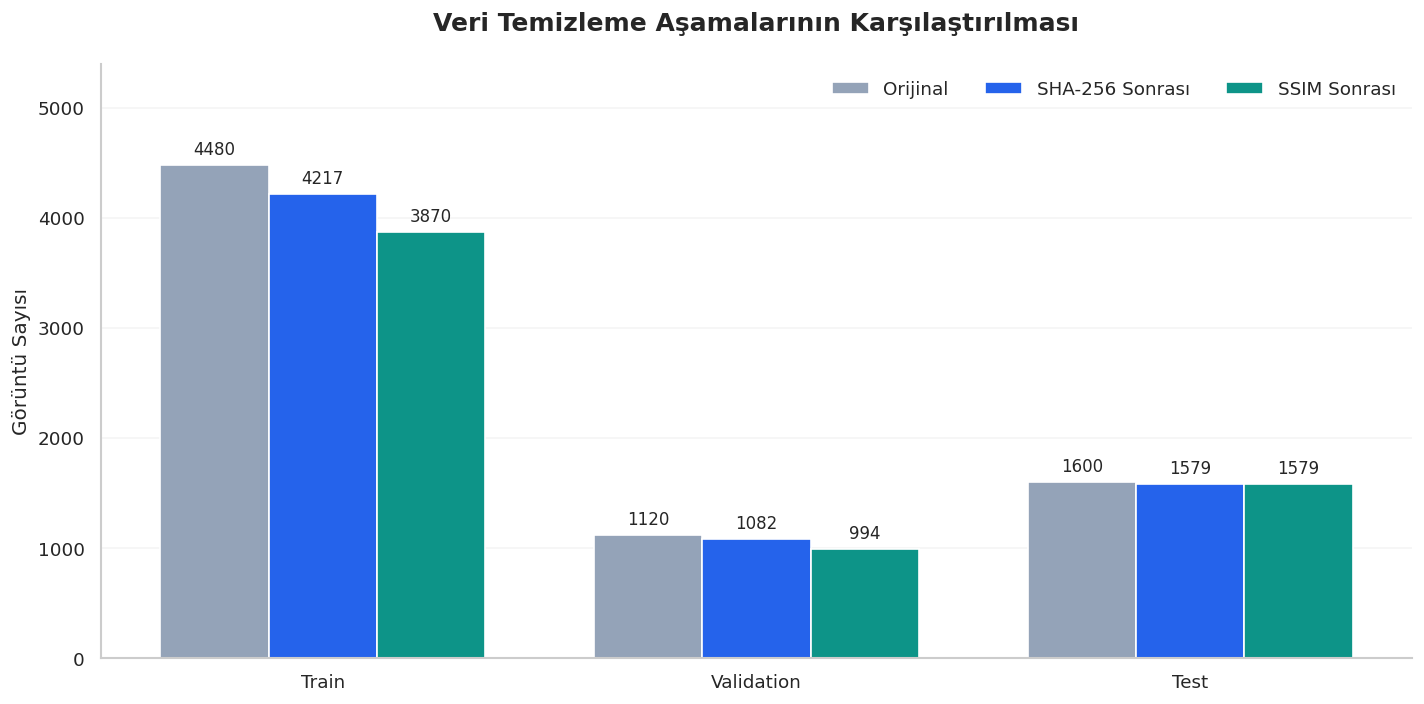

Kaydedildi: 01_veri_temizleme_karsilastirma.png


In [13]:
# ==================================================
# 9.2. VERİ TEMİZLEME KARŞILAŞTIRMASI
# ==================================================

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(3)
width = 0.25

gruplar = ["Train", "Validation", "Test"]

for i, (sutun, etiket, renk) in enumerate([
    ("Orijinal", "Orijinal", "#94A3B8"),
    ("SHA256 Sonrasi", "SHA-256 Sonrası", "#2563EB"),
    ("SSIM Sonrasi", "SSIM Sonrası", "#0D9488")
]):

    bars = ax.bar(
        x + (i - 1) * width,
        final_ozet.iloc[:3][sutun],
        width=width,
        label=etiket,
        color=renk
    )

    ax.bar_label(
        bars,
        padding=4,
        fontsize=10
    )

ax.set_title(
    "Veri Temizleme Aşamalarının Karşılaştırılması",
    pad=20
)

ax.set_ylabel("Görüntü Sayısı")
ax.set_xticks(x)
ax.set_xticklabels(gruplar)
ax.set_ylim(0, 5400)

ax.legend(
    loc="upper right",
    ncol=3
)

ax.grid(axis="x", visible=False)

fig.tight_layout()

grafik_kaydet(
    fig,
    "01_veri_temizleme_karsilastirma.png"
)

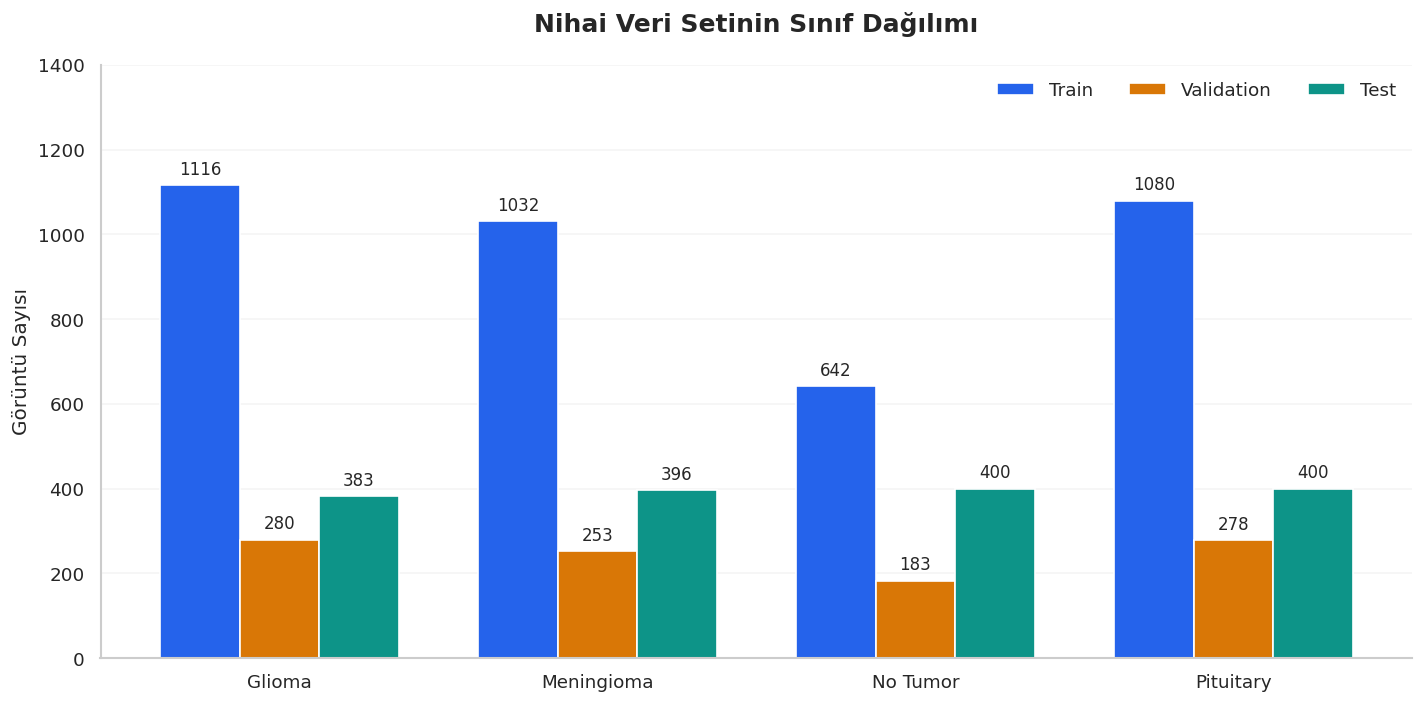

Kaydedildi: 02_nihai_sinif_dagilimi.png


In [14]:
# ==================================================
# 9.3. SINIF DAĞILIMI
# ==================================================

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(4)
width = 0.25

for i, grup in enumerate([
    "Train",
    "Validation",
    "Test"
]):

    bars = ax.bar(
        x + (i - 1) * width,
        final_sinif_dagilimi[grup],
        width=width,
        label=grup,
        color=RENKLER[grup]
    )

    ax.bar_label(
        bars,
        padding=4,
        fontsize=10
    )

ax.set_title(
    "Nihai Veri Setinin Sınıf Dağılımı",
    pad=20
)

ax.set_ylabel("Görüntü Sayısı")

ax.set_xticks(x)

ax.set_xticklabels([
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
])

ax.set_ylim(0, 1400)
ax.legend(ncol=3, loc="upper right")
ax.grid(axis="x", visible=False)

fig.tight_layout()

grafik_kaydet(
    fig,
    "02_nihai_sinif_dagilimi.png"
)

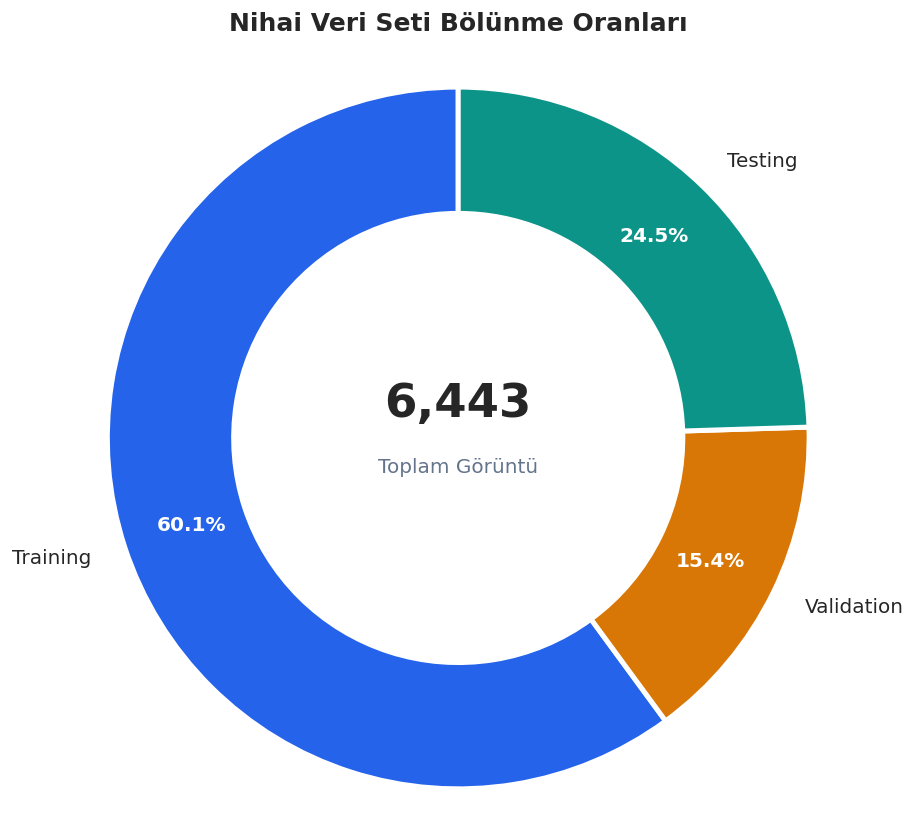

Kaydedildi: 03_veri_seti_bolunme_oranlari.png


In [15]:
# ==================================================
# 9.4. VERİ SETİ BÖLÜNME ORANLARI
# ==================================================

fig, ax = plt.subplots(figsize=(8, 7))

sayilar = [
    len(train_final),
    len(val_final),
    len(test_final)
]

etiketler = [
    "Training",
    "Validation",
    "Testing"
]

wedges, texts, autotexts = ax.pie(
    sayilar,
    labels=etiketler,
    colors=[
        RENKLER["Train"],
        RENKLER["Validation"],
        RENKLER["Test"]
    ],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={
        "width": 0.36,
        "edgecolor": "white",
        "linewidth": 3
    },
    textprops={
        "fontsize": 12
    }
)

for text in autotexts:
    text.set_color("white")
    text.set_fontweight("bold")

ax.text(
    0, 0.06,
    f"{sum(sayilar):,}",
    ha="center",
    fontsize=28,
    fontweight="bold"
)

ax.text(
    0, -0.10,
    "Toplam Görüntü",
    ha="center",
    fontsize=12,
    color="#64748B"
)

ax.set_title(
    "Nihai Veri Seti Bölünme Oranları",
    pad=20
)

ax.axis("equal")

fig.tight_layout()

grafik_kaydet(
    fig,
    "03_veri_seti_bolunme_oranlari.png"
)

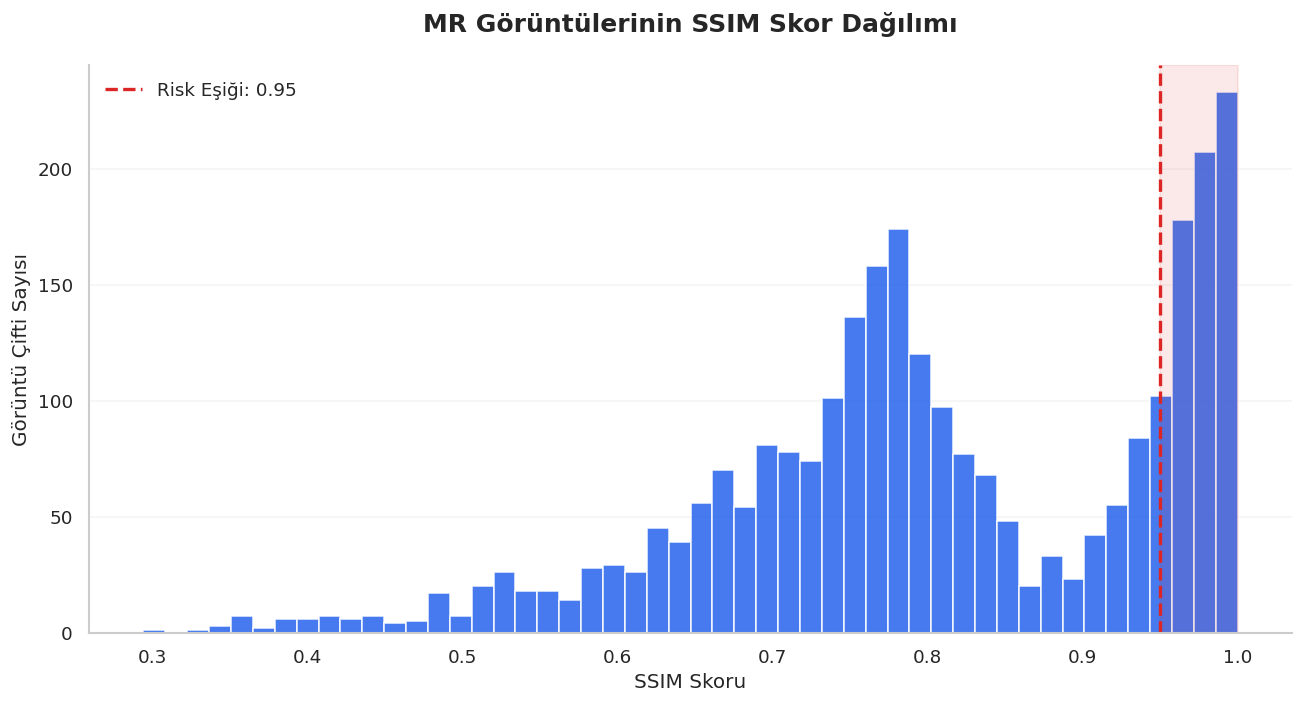

Kaydedildi: 04_ssim_skor_dagilimi.png


In [16]:
# ==================================================
# 9.5. SSIM BENZERLİK ANALİZİ GRAFİĞİ
# ==================================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    ssim_df["ssim"],
    bins=50,
    color="#2563EB",
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    0.95,
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label="Risk Eşiği: 0.95"
)

ax.axvspan(
    0.95,
    1.0,
    color="#DC2626",
    alpha=0.10
)

ax.set_title(
    "MR Görüntülerinin SSIM Skor Dağılımı",
    pad=20
)

ax.set_xlabel("SSIM Skoru")
ax.set_ylabel("Görüntü Çifti Sayısı")

ax.legend()
ax.grid(axis="x", visible=False)

fig.tight_layout()

grafik_kaydet(
    fig,
    "04_ssim_skor_dagilimi.png"
)

In [17]:
# ==================================================
# 10. VERİ ÖN İŞLEME DOSYALARININ DÜZENLENMESİ
# ==================================================

import shutil

preprocessing_klasoru = (
    proje_yolu / "results" / "Data_Preprocessing"
)

preprocessing_klasoru.mkdir(
    parents=True,
    exist_ok=True
)

dosyalar = [
    "veri_kontrolu.csv",
    "benzer_goruntu_kontrolu.csv",
    "ssim_analizi.csv",
    "ssim_goruntu_karsilastirma.png",
    "01_veri_temizleme_karsilastirma.png",
    "02_nihai_sinif_dagilimi.png",
    "03_veri_seti_bolunme_oranlari.png",
    "04_ssim_skor_dagilimi.png"
]

for dosya in dosyalar:

    kaynak = sonuc_klasoru / dosya
    hedef = preprocessing_klasoru / dosya

    if kaynak.exists():

        shutil.copy2(kaynak, hedef)
        print("Kopyalandı:", dosya)

    else:

        print("Bulunamadı:", dosya)

print("\nVeri ön işleme sonuç klasörü:")
print(preprocessing_klasoru)

print("\nOrijinal dosyalar korundu.")

Kopyalandı: veri_kontrolu.csv
Kopyalandı: benzer_goruntu_kontrolu.csv
Kopyalandı: ssim_analizi.csv
Bulunamadı: ssim_goruntu_karsilastirma.png
Kopyalandı: 01_veri_temizleme_karsilastirma.png
Kopyalandı: 02_nihai_sinif_dagilimi.png
Kopyalandı: 03_veri_seti_bolunme_oranlari.png
Kopyalandı: 04_ssim_skor_dagilimi.png

Veri ön işleme sonuç klasörü:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/Data_Preprocessing

Orijinal dosyalar korundu.
